In [1016]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [1017]:
df=pd.read_csv('C:/Users/hP/downloads/train.csv')
df=df.drop('id',axis=1)
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,42,technician,married,secondary,no,7,no,no,cellular,25,aug,117,3,-1,0,unknown,0
1,38,blue-collar,married,secondary,no,514,no,no,unknown,18,jun,185,1,-1,0,unknown,0
2,36,blue-collar,married,secondary,no,602,yes,no,unknown,14,may,111,2,-1,0,unknown,0
3,27,student,single,secondary,no,34,yes,no,unknown,28,may,10,2,-1,0,unknown,0
4,26,technician,married,secondary,no,889,yes,no,cellular,3,feb,902,1,-1,0,unknown,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
749995,29,services,single,secondary,no,1282,no,yes,unknown,4,jul,1006,2,-1,0,unknown,1
749996,69,retired,divorced,tertiary,no,631,no,no,cellular,19,aug,87,1,-1,0,unknown,0
749997,50,blue-collar,married,secondary,no,217,yes,no,cellular,17,apr,113,1,-1,0,unknown,0
749998,32,technician,married,secondary,no,-274,no,no,cellular,26,aug,108,6,-1,0,unknown,0


In [1018]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [1019]:
def Dropoutliers(data,col1,col2,vcol2,q1,q2,data2=None):
  if isinstance(data2, pd.DataFrame):
    data_temp=pd.concat([data,data2],axis=1)
  else:
    data_temp=data
  Q_2=data.loc[data_temp[col2]==vcol2,col1].quantile(q2)
  Q_1=data.loc[data_temp[col2]==vcol2,col1].quantile(q1)
  indecies=data_temp[((data_temp[col1]>Q_2)|(data_temp[col1]<Q_1))&(data_temp[col2]==vcol2)].index
  data.drop(indecies,inplace=True)
  if isinstance(data2, pd.DataFrame):
    data2.drop(indecies,inplace=True)

In [1020]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750000 entries, 0 to 749999
Data columns (total 17 columns):
 #   Column     Non-Null Count   Dtype 
---  ------     --------------   ----- 
 0   age        750000 non-null  int64 
 1   job        750000 non-null  object
 2   marital    750000 non-null  object
 3   education  750000 non-null  object
 4   default    750000 non-null  object
 5   balance    750000 non-null  int64 
 6   housing    750000 non-null  object
 7   loan       750000 non-null  object
 8   contact    750000 non-null  object
 9   day        750000 non-null  int64 
 10  month      750000 non-null  object
 11  duration   750000 non-null  int64 
 12  campaign   750000 non-null  int64 
 13  pdays      750000 non-null  int64 
 14  previous   750000 non-null  int64 
 15  poutcome   750000 non-null  object
 16  y          750000 non-null  int64 
dtypes: int64(8), object(9)
memory usage: 97.3+ MB


In [1021]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous,y
count,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000,750000.000000
mean,40.926395,1204.067397,16.117209,256.229144,2.577008,22.412733,0.298545,0.120651
std,10.098829,2836.096759,8.250832,272.555662,2.718514,77.319998,1.335926,0.325721
min,18.000000,-8019.000000,1.000000,1.000000,1.000000,-1.000000,0.000000,0.000000
25%,33.000000,0.000000,9.000000,91.000000,1.000000,-1.000000,0.000000,0.000000
50%,39.000000,634.000000,17.000000,133.000000,2.000000,-1.000000,0.000000,0.000000
75%,48.000000,1390.000000,21.000000,361.000000,3.000000,-1.000000,0.000000,0.000000
max,95.000000,99717.000000,31.000000,4918.000000,63.000000,871.000000,200.000000,1.000000


<Axes: >

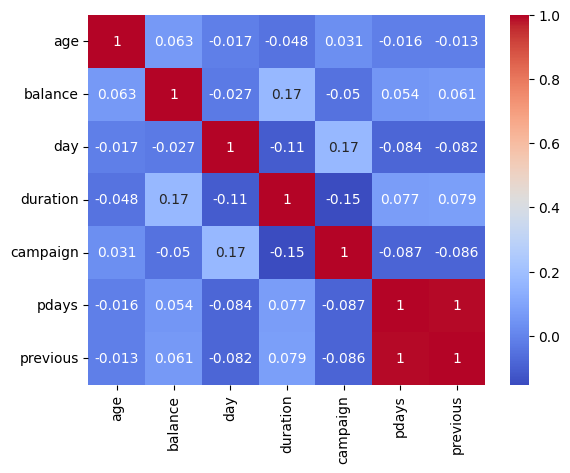

In [1022]:
numerical_features=df.select_dtypes(include=['int64','float64'])
numerical_features=numerical_features.drop('y',axis=1)
corr=numerical_features.corr(method='spearman')
sns.heatmap(corr,annot=True,cmap='coolwarm')

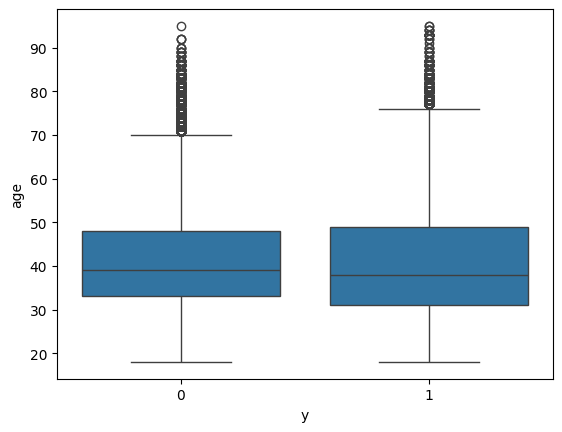

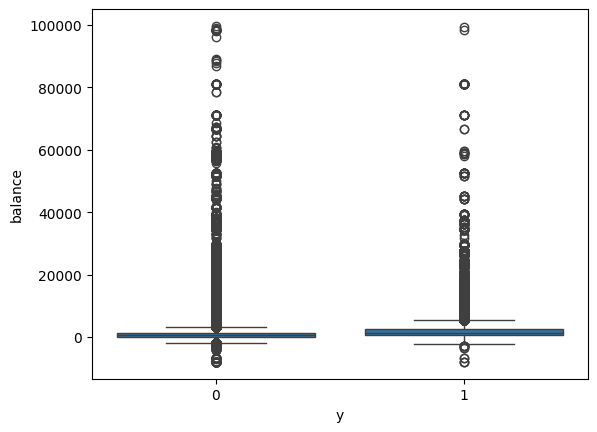

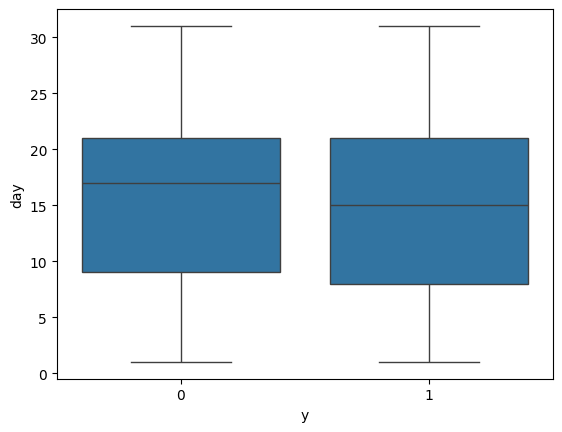

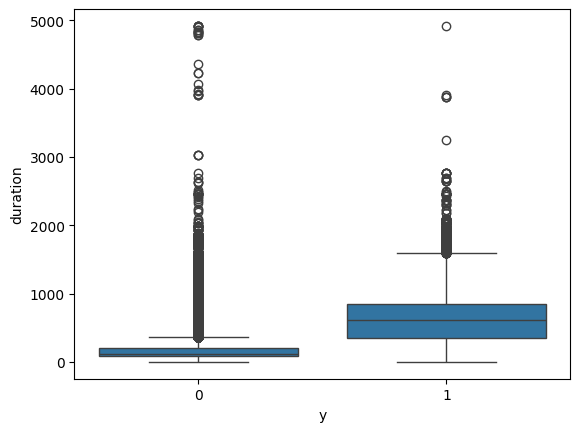

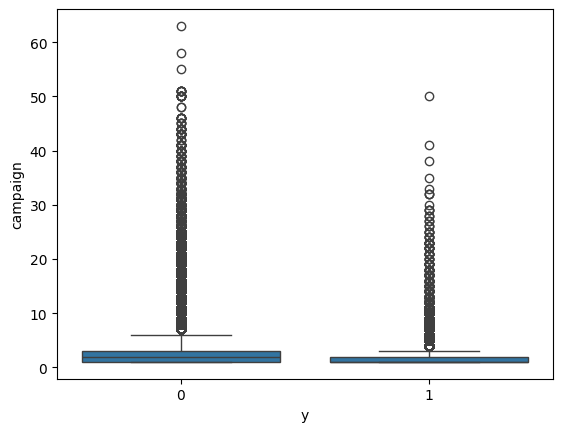

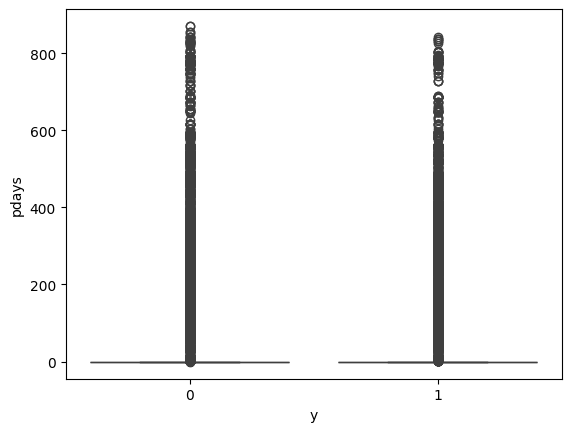

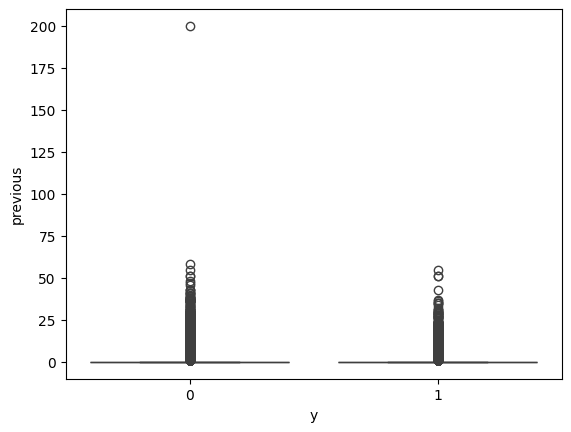

In [1023]:
for i in numerical_features.columns:
    sns.boxplot(x='y',y=i,data=df)
    plt.show()


In [1024]:
# for i in numerical_features.columns:
#     sns.boxplot(x='y',y=i,data=df)
#     plt.show()

In [1025]:
df.replace('unknown',np.nan,inplace=True)
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,42,technician,married,secondary,no,7,no,no,cellular,25,aug,117,3,-1,0,NaN,0
1,38,blue-collar,married,secondary,no,514,no,no,NaN,18,jun,185,1,-1,0,NaN,0
2,36,blue-collar,married,secondary,no,602,yes,no,NaN,14,may,111,2,-1,0,NaN,0
3,27,student,single,secondary,no,34,yes,no,NaN,28,may,10,2,-1,0,NaN,0
4,26,technician,married,secondary,no,889,yes,no,cellular,3,feb,902,1,-1,0,NaN,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
749995,29,services,single,secondary,no,1282,no,yes,NaN,4,jul,1006,2,-1,0,NaN,1
749996,69,retired,divorced,tertiary,no,631,no,no,cellular,19,aug,87,1,-1,0,NaN,0
749997,50,blue-collar,married,secondary,no,217,yes,no,cellular,17,apr,113,1,-1,0,NaN,0
749998,32,technician,married,secondary,no,-274,no,no,cellular,26,aug,108,6,-1,0,NaN,0


In [1026]:
categorical_features=df.select_dtypes(include=['object'])
col=list(categorical_features.columns)
print(col)
for i in col:
    df[i].fillna(df[i].mode()[0],inplace=True)
df

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


C:\Users\hP\AppData\Local\Temp\ipykernel_12156\1038016514.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[i].fillna(df[i].mode()[0],inplace=True)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,42,technician,married,secondary,no,7,no,no,cellular,25,aug,117,3,-1,0,failure,0
1,38,blue-collar,married,secondary,no,514,no,no,cellular,18,jun,185,1,-1,0,failure,0
2,36,blue-collar,married,secondary,no,602,yes,no,cellular,14,may,111,2,-1,0,failure,0
3,27,student,single,secondary,no,34,yes,no,cellular,28,may,10,2,-1,0,failure,0
4,26,technician,married,secondary,no,889,yes,no,cellular,3,feb,902,1,-1,0,failure,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
749995,29,services,single,secondary,no,1282,no,yes,cellular,4,jul,1006,2,-1,0,failure,1
749996,69,retired,divorced,tertiary,no,631,no,no,cellular,19,aug,87,1,-1,0,failure,0
749997,50,blue-collar,married,secondary,no,217,yes,no,cellular,17,apr,113,1,-1,0,failure,0
749998,32,technician,married,secondary,no,-274,no,no,cellular,26,aug,108,6,-1,0,failure,0


In [1027]:
categorical_features.nunique()

job          11
marital       3
education     3
default       2
housing       2
loan          2
contact       2
month        12
poutcome      3
dtype: int64

In [1028]:
X=df.drop('y',axis=1)
y=df['y']

In [1029]:
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler,PolynomialFeatures,LabelEncoder,OneHotEncoder
from sklearn.compose import ColumnTransformer
categorical_features=X.select_dtypes(include='object').drop('education',axis =1).columns
numerical_features=X.select_dtypes(include=['int64','float64']).columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(drop='first',sparse_output=False,handle_unknown="ignore"), categorical_features)
    ],remainder='drop'
)

# Apply transformation
X_t = preprocessor.fit_transform(X)

X_train=pd.DataFrame(X_t,columns=preprocessor.get_feature_names_out(),index=X.index)
Encoder={}
e=LabelEncoder()
X_train['education']=e.fit_transform(X['education'])
Encoder['education']=e


In [1030]:
X

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,42,technician,married,secondary,no,7,no,no,cellular,25,aug,117,3,-1,0,failure
1,38,blue-collar,married,secondary,no,514,no,no,cellular,18,jun,185,1,-1,0,failure
2,36,blue-collar,married,secondary,no,602,yes,no,cellular,14,may,111,2,-1,0,failure
3,27,student,single,secondary,no,34,yes,no,cellular,28,may,10,2,-1,0,failure
4,26,technician,married,secondary,no,889,yes,no,cellular,3,feb,902,1,-1,0,failure
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
749995,29,services,single,secondary,no,1282,no,yes,cellular,4,jul,1006,2,-1,0,failure
749996,69,retired,divorced,tertiary,no,631,no,no,cellular,19,aug,87,1,-1,0,failure
749997,50,blue-collar,married,secondary,no,217,yes,no,cellular,17,apr,113,1,-1,0,failure
749998,32,technician,married,secondary,no,-274,no,no,cellular,26,aug,108,6,-1,0,failure


In [1031]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier

In [1032]:
y.value_counts()

y
0    659512
1     90488
Name: count, dtype: int64

In [1033]:
# DT = DecisionTreeClassifier(criterion="gini")
# param_grid = {'max_depth': list(range(3,50))}
# grid_search=GridSearchCV(DT,param_grid,cv=5)
# grid_search.fit(X_for_Decision_tree,y)
# depth=grid_search.best_params_['max_depth']
# DT = DecisionTreeClassifier(criterion="gini",max_depth=depth)
# DT.fit(X_for_Decision_tree,y)

In [1034]:
# RF=RandomForestClassifier(n_estimators=100,criterion='gini')
# RF.fit(X_for_Decision_tree_train,y_for_Decision_tree_train)
# y_pred = RF.predict(X_for_Decision_tree_test)
# accuracy = accuracy_score(y_for_Decision_tree_test, y_pred)
# print(f"The accuracy of the test of RandomForest={accuracy}")
# print(classification_report(y_for_Decision_tree_test, y_pred))

In [1035]:
logistic_model= LogisticRegression()
logistic_model.fit(X_train,y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [1036]:
test_data=pd.read_csv('C:/Users/hP/downloads/test.csv')
test_data


,id,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,750000,32,blue-collar,married,secondary,no,1397,yes,no,unknown,21,may,224,1,-1,0,unknown
1,750001,44,management,married,tertiary,no,23,yes,no,cellular,3,apr,586,2,-1,0,unknown
2,750002,36,self-employed,married,primary,no,46,yes,yes,cellular,13,may,111,2,-1,0,unknown
3,750003,58,blue-collar,married,secondary,no,-1380,yes,yes,unknown,29,may,125,1,-1,0,unknown
4,750004,28,technician,single,secondary,no,1950,yes,no,cellular,22,jul,181,1,-1,0,unknown
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,999995,43,management,married,tertiary,no,0,yes,no,cellular,18,nov,65,2,-1,0,unknown
249996,999996,40,services,married,unknown,no,522,yes,no,cellular,19,nov,531,1,189,1,failure
249997,999997,63,retired,married,primary,no,33,no,no,cellular,3,jul,178,1,92,8,success
249998,999998,50,blue-collar,married,primary,no,2629,yes,no,unknown,30,may,163,2,-1,0,unknown


In [1037]:
ids=test_data['id']
ids

0         750000
1         750001
2         750002
3         750003
4         750004
           ...  
249995    999995
249996    999996
249997    999997
249998    999998
249999    999999
Name: id, Length: 250000, dtype: int64

In [1038]:
test_data=test_data.drop('id',axis=1)


In [1039]:
test_data.replace('unknown',np.nan,inplace=True)
categorical_features=test_data.select_dtypes(include=['object'])
col=list(categorical_features.columns)
print(col)
for i in col:
    test_data[i].fillna(test_data[i].mode()[0],inplace=True)
test_data

['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


C:\Users\hP\AppData\Local\Temp\ipykernel_12156\2923127911.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  test_data[i].fillna(test_data[i].mode()[0],inplace=True)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome
0,32,blue-collar,married,secondary,no,1397,yes,no,cellular,21,may,224,1,-1,0,failure
1,44,management,married,tertiary,no,23,yes,no,cellular,3,apr,586,2,-1,0,failure
2,36,self-employed,married,primary,no,46,yes,yes,cellular,13,may,111,2,-1,0,failure
3,58,blue-collar,married,secondary,no,-1380,yes,yes,cellular,29,may,125,1,-1,0,failure
4,28,technician,single,secondary,no,1950,yes,no,cellular,22,jul,181,1,-1,0,failure
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249995,43,management,married,tertiary,no,0,yes,no,cellular,18,nov,65,2,-1,0,failure
249996,40,services,married,secondary,no,522,yes,no,cellular,19,nov,531,1,189,1,failure
249997,63,retired,married,primary,no,33,no,no,cellular,3,jul,178,1,92,8,success
249998,50,blue-collar,married,primary,no,2629,yes,no,cellular,30,may,163,2,-1,0,failure


In [1040]:
categorical_features=test_data.select_dtypes(include='object').drop('education',axis =1).columns
numerical_features=test_data.select_dtypes(include=['int64','float64']).columns


# Apply transformation
X_t = preprocessor.transform(test_data)

X_test=pd.DataFrame(X_t,columns=preprocessor.get_feature_names_out(),index=test_data.index)
X_test['education']=Encoder['education'].transform(test_data['education'])


   

In [1041]:
y_pred=logistic_model.predict_proba(X_test)[::,1]
pred=pd.Series(y_pred)

In [1042]:
sub_df=pd.concat([ids,pred],axis=1)
sub_df.rename(columns={0: "y"},inplace=True)
sub_df

,id,y
0,750000,0.017232
1,750001,0.340936
2,750002,0.003122
3,750003,0.003754
4,750004,0.027587
...,...,...
249995,999995,0.009795
249996,999996,0.078444
249997,999997,0.609146
249998,999998,0.007559


In [1043]:
sub_df.to_csv("submission.csv", index=False) 